# A. How the choice-only GLM-HMM relates to the DDM-HMM

Analysis A of `README.md`. Both models are fitted per mouse from behaviour alone:
- **GLM-HMM** (K = 2, the paper's model): choice only. A trial is *engaged* when P(engaged) ≥ 0.5, otherwise *lapse*.
- **DDM-HMM** (K = 4, the collaborator's): choice + reaction time. States are named engaged / slow / impulsive / biased-L / biased-R / disengaged by `dh.name_state`, as in `../2_ddm_hmm_states.ipynb`. *Omission* = the no-go state of the new-format fits.

Question: which distinctions does the choice-only model miss? Expected: GLM *lapse* = DDM disengaged + impulsive + biased, and GLM *engaged* = DDM engaged + slow. Only the 8 mice with a DDM-HMM fit are used. Each mouse counts equally.

In [1]:
import sys, pathlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO = pathlib.Path.cwd().resolve()
while not (REPO / 'Functions' / 'nm_syllables.py').exists() and REPO != REPO.parent:
    REPO = REPO.parent
sys.path.insert(0, str(REPO)); sys.path.insert(0, str(REPO / 'neuromodulators' / 'behavioural_states'))
import states as st
warnings.filterwarnings('ignore')

T = st.aligned()
KINDS = [k for k in st.KIND_ORDER if k in T['kind'].unique()]
MICE = sorted(T['subject'].unique())
NM = T.groupby('subject')['target_NM'].first()
easy = T['contrast'] >= 25
summary = T.groupby('subject').agg(NM=('target_NM', 'first'), sessions=('eid', 'nunique'), trials=('trial', 'size'),
                                   format=('format', 'first'), p_lapse=('glm_state', lambda s: (s == 'lapse').mean()))
summary['easy acc, GLM engaged'] = T[easy & (T.glm_state == 'engaged')].groupby('subject')['correct'].mean()
summary['easy acc, GLM lapse'] = T[easy & (T.glm_state == 'lapse')].groupby('subject')['correct'].mean()
summary.round(2)

,NM,sessions,trials,format,p_lapse,"easy acc, GLM engaged","easy acc, GLM lapse"
subject,,,,,,,
ZFM-04019,SNc-DA,20,14612,new,0.08,0.97,0.50
ZFM-06271,LC-NE,1,502,legacy,0.41,0.92,0.79
ZFM-08776,LC-NE,33,22910,legacy,0.35,0.95,0.65
ZFM-08818,VTA-DA,21,18748,new,0.25,0.96,0.47
ZFM-08871,LC-NE,35,29148,new,0.38,0.86,0.87
ZFM-09365,DR-5HT,43,30334,new,0.12,0.98,0.42
ZFM-09394,VTA-DA,46,39158,new,0.21,0.98,0.61
ZFM-09439,DR-5HT,41,35738,new,0.08,0.95,0.23


The last two columns check the GLM-HMM: its engaged state should be accurate on easy trials (≥ 25% contrast) and its lapse state much less so. Where the two are close, the GLM-HMM did not find an engagement axis in that mouse; its states are something else (e.g. side bias), so its row below should be read with that in mind.

## DDM kinds inside each GLM-HMM state

Left: per mouse, what the GLM-HMM *engaged* and *lapse* trials are made of, in DDM kinds. Right: the same, averaged over mice.

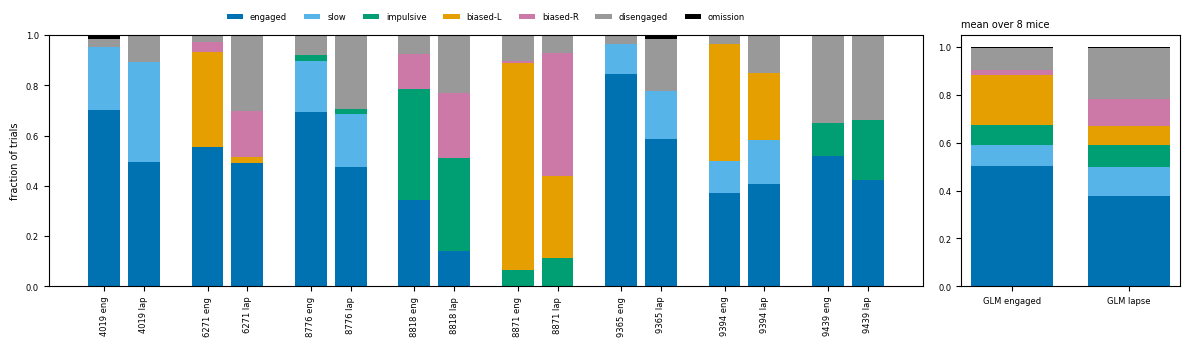

kind,engaged,slow,impulsive,biased-L,biased-R,disengaged,omission
glm_state,,,,,,,
engaged,0.50,0.09,0.08,0.21,0.02,0.09,0.0
lapse,0.38,0.12,0.09,0.08,0.12,0.21,0.0


In [2]:
a, b = st.crosstab(T)
P = a.pivot_table(index=['subject', 'glm_state'], columns='kind', values='p', fill_value=0)[KINDS]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={'width_ratios': [4, 1]})
ax = axes[0]
x = 0; ticks, labels = [], []
for m in MICE:
    for gs in ['engaged', 'lapse']:
        if (m, gs) not in P.index:
            continue
        bottom = 0
        for k in KINDS:
            v = P.loc[(m, gs), k]
            ax.bar(x, v, bottom=bottom, color=st.KIND_COLORS[k], width=0.8, label=k if x == 0 else None)
            bottom += v
        ticks.append(x); labels.append(f"{m[-4:]} {gs[:3]}")
        x += 1
    x += 0.6
ax.set_xticks(ticks, labels, rotation=90, fontsize=6); ax.set_ylabel('fraction of trials', fontsize=7)
ax.tick_params(labelsize=6); ax.legend(fontsize=6, frameon=False, ncol=len(KINDS), loc='upper center', bbox_to_anchor=(0.5, 1.12))
ax = axes[1]
mean = P.groupby('glm_state').mean()
for x, gs in enumerate(['engaged', 'lapse']):
    bottom = 0
    for k in KINDS:
        ax.bar(x, mean.loc[gs, k], bottom=bottom, color=st.KIND_COLORS[k], width=0.7)
        bottom += mean.loc[gs, k]
ax.set_xticks([0, 1], ['GLM engaged', 'GLM lapse'], fontsize=6); ax.tick_params(labelsize=6)
ax.set_title(f'mean over {len(MICE)} mice', fontsize=7, loc='left')
plt.tight_layout(); plt.show()
mean.round(2)

## How much of each DDM kind the GLM-HMM calls engaged

Per DDM kind, the mean P(engaged) of its trials (soft, no threshold). One dot per mouse; bar = mean over mice. A kind the GLM-HMM cannot see would sit at the same level as engaged.

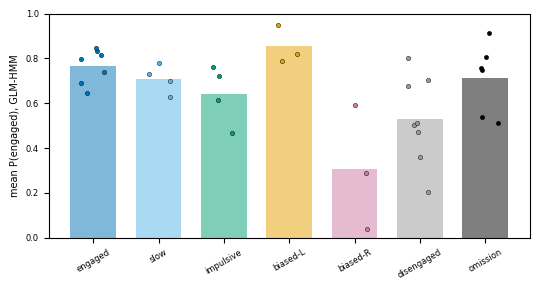

kind,engaged,slow,impulsive,biased-L,biased-R,disengaged,omission
subject,,,,,,,
ZFM-04019,0.83,0.78,NaN,NaN,NaN,0.70,0.81
ZFM-06271,0.65,NaN,NaN,0.95,0.29,0.21,NaN
ZFM-08776,0.69,0.63,0.62,NaN,NaN,0.36,NaN
ZFM-08818,0.80,NaN,0.72,NaN,0.59,0.50,0.76
ZFM-08871,NaN,NaN,0.47,0.79,0.04,0.68,0.75
ZFM-09365,0.81,0.73,NaN,NaN,NaN,0.51,0.54
ZFM-09394,0.74,0.70,NaN,0.82,NaN,0.47,0.51
ZFM-09439,0.85,NaN,0.76,NaN,NaN,0.80,0.91


In [3]:
pe = T.groupby(['subject', 'kind'])['p_engaged'].mean().unstack()[KINDS]
fig, ax = plt.subplots(figsize=(5.5, 3))
for j, k in enumerate(KINDS):
    v = pe[k].dropna()
    ax.bar(j, v.mean(), color=st.KIND_COLORS[k], alpha=0.5, width=0.7)
    ax.scatter(j + np.random.default_rng(j).uniform(-0.2, 0.2, len(v)), v, s=10, color=st.KIND_COLORS[k], ec='k', lw=0.3)
ax.set_xticks(range(len(KINDS)), KINDS, fontsize=6, rotation=30); ax.set_ylabel('mean P(engaged), GLM-HMM', fontsize=7)
ax.set_ylim(0, 1); ax.tick_params(labelsize=6)
plt.tight_layout(); plt.show()
pe.round(2)

## How much does one model tell about the other?

Conditional entropy per mouse. *Fraction left* = H(target | given) / H(target): 1 means knowing the given model's state tells nothing about the target, 0 means it determines it. The DDM-HMM has more states, so H(DDM | GLM) is expected to stay high. The informative number is how *much* of the DDM partition the GLM-HMM recovers.

In [4]:
h1 = st.conditional_entropy(T, 'glm_state', 'kind').set_index('subject')
h2 = st.conditional_entropy(T, 'kind', 'glm_state').set_index('subject')
out = pd.concat({'DDM kind given GLM state': h1, 'GLM state given DDM kind': h2}, axis=1).round(2)
out.loc['mean'] = out.mean()
out

DDM kind given GLM state                                    \
                           H(kind) H(kind | glm_state) fraction left   
subject                                                                
ZFM-04019                  1.15000             1.14000        0.9900   
ZFM-06271                  1.70000             1.44000        0.8500   
ZFM-08776                  1.44000             1.38000        0.9600   
ZFM-08818                  1.84000             1.78000        0.9700   
ZFM-08871                  1.50000             1.19000        0.8000   
ZFM-09365                  0.88000             0.84000        0.9500   
ZFM-09394                  1.70000             1.66000        0.9800   
ZFM-09439                  1.42000             1.42000        1.0000   
mean                       1.45375             1.35625        0.9375   

          GLM state given DDM kind                                    
                      H(glm_state) H(glm_state | kind) fraction left  
subject                                                               
ZFM-04019                    0.400             0.39000       0.97000  
ZFM-06271                    0.970             0.71000       0.73000  
ZFM-08776                    0.930             0.87000       0.94000  
ZFM-08818                    0.810             0.75000       0.93000  
ZFM-08871                    0.960             0.65000       0.68000  
ZFM-09365                    0.520             0.48000       0.92000  
ZFM-09394                    0.730             0.70000       0.95000  
ZFM-09439                    0.400             0.40000       0.99000  
mean                         0.715             0.61875       0.88875

## What the GLM-HMM lumps together

Within each GLM-HMM state, the DDM kinds compared on behaviour the choice model doesn't use, plus accuracy. Per mouse (dots), cells with ≥ 50 trials; bar = mean over mice.
- median RT (response − stimulus onset, s);
- easy-trial accuracy (≥ 25% contrast);
- P(repeat previous choice);
- position in session.

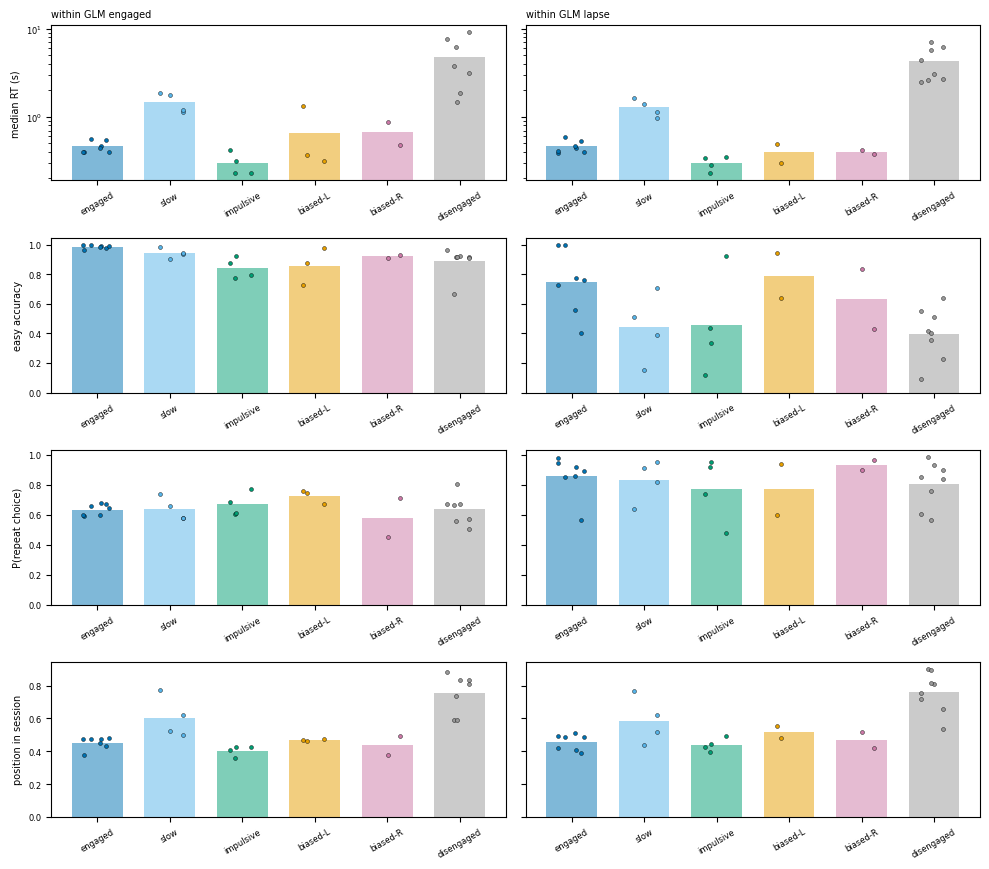

median RT (s)  easy accuracy  P(repeat choice)  \
glm_state kind                                                         
engaged   biased-L             0.66           0.86              0.73   
          biased-R             0.68           0.92              0.58   
          disengaged           4.76           0.89              0.64   
          engaged              0.46           0.99              0.63   
          impulsive            0.30           0.84              0.67   
          slow                 1.49           0.94              0.64   
lapse     biased-L             0.39           0.79              0.77   
          biased-R             0.40           0.63              0.93   
          disengaged           4.28           0.40              0.80   
          engaged              0.46           0.75              0.86   
          impulsive            0.30           0.45              0.77   
          slow                 1.28           0.44              0.83   

                      position in session         n  
glm_state kind                                       
engaged   biased-L                   0.47   9786.00  
          biased-R                   0.44   1054.50  
          disengaged                 0.75   2565.29  
          engaged                    0.45  10860.71  
          impulsive                  0.40   2999.25  
          slow                       0.60   3413.50  
lapse     biased-L                   0.52   2902.00  
          biased-R                   0.47   3319.00  
          disengaged                 0.76    916.75  
          engaged                    0.46   1667.57  
          impulsive                  0.44    969.50  
          slow                       0.59   1059.00

In [5]:
def feats(g):
    return pd.Series({'median RT (s)': g['rt'].median(), 'easy accuracy': g.loc[g['contrast'] >= 25, 'correct'].mean(),
                      'P(repeat choice)': g['repeat'].mean(), 'position in session': g['trial_frac'].mean(), 'n': len(g)})
F = T[T['kind'] != 'omission'].groupby(['subject', 'glm_state', 'kind']).apply(feats).reset_index()
F = F[F['n'] >= 50]
COLS = ['median RT (s)', 'easy accuracy', 'P(repeat choice)', 'position in session']
fig, axes = plt.subplots(len(COLS), 2, figsize=(10, 2.2 * len(COLS)), sharey='row')
for i, c in enumerate(COLS):
    for j, gs in enumerate(['engaged', 'lapse']):
        ax = axes[i, j]
        d = F[F['glm_state'] == gs]
        ks = [k for k in KINDS if k in d['kind'].unique()]
        for x, k in enumerate(ks):
            v = d.loc[d['kind'] == k, c]
            ax.bar(x, v.mean(), color=st.KIND_COLORS[k], alpha=0.5, width=0.7)
            ax.scatter(x + np.random.default_rng(x).uniform(-0.2, 0.2, len(v)), v, s=8, color=st.KIND_COLORS[k], ec='k', lw=0.3)
        ax.set_xticks(range(len(ks)), ks, fontsize=6, rotation=30); ax.tick_params(labelsize=6)
        if i == 0:
            ax.set_title(f'within GLM {gs}', fontsize=7, loc='left')
        if j == 0:
            ax.set_ylabel(c, fontsize=7)
    if c == 'median RT (s)':
        axes[i, 0].set_yscale('log')
plt.tight_layout(); plt.show()
F.groupby(['glm_state', 'kind'])[COLS + ['n']].mean().round(2)

## Over the session

Mean over mice of the fraction of trials in each DDM kind (stacked) and of GLM-HMM lapse (black line), in tenths of the session.

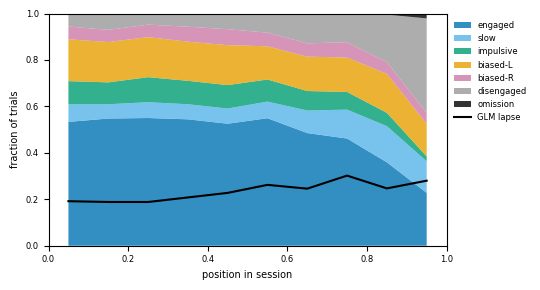

In [6]:
T['bin'] = np.minimum((T['trial_frac'] * 10).astype(int), 9)
occ = T.groupby(['subject', 'bin'])['kind'].value_counts(normalize=True).unstack(fill_value=0)[KINDS].groupby('bin').mean()
lapse = T.groupby(['subject', 'bin'])['glm_state'].apply(lambda s: (s == 'lapse').mean()).groupby('bin').mean()
fig, ax = plt.subplots(figsize=(5.5, 3))
x = (np.arange(10) + 0.5) / 10
ax.stackplot(x, occ.T.to_numpy(), colors=[st.KIND_COLORS[k] for k in KINDS], labels=KINDS, alpha=0.8)
ax.plot(x, lapse, color='k', lw=1.5, label='GLM lapse')
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_xlabel('position in session', fontsize=7); ax.set_ylabel('fraction of trials', fontsize=7)
ax.tick_params(labelsize=6); ax.legend(fontsize=6, frameon=False, bbox_to_anchor=(1, 1), loc='upper left')
plt.tight_layout(); plt.show()

## Example sessions: both models trial by trial

One session per mouse: the one with the median number of trials among that mouse's sessions. Panels, top to bottom:
1. **GLM-HMM** P(engaged), with the 0.5 threshold. Shading marks lapse runs.
2. **Accuracy**: rolling fraction correct over 11 trials (black; no-go trials count as errors) and over 7 easy trials (≥ 25% contrast, green). Easy-trial accuracy is the cleaner lapse signal, since hard trials are often wrong in any state.
3. **DDM-HMM** kind of each trial (Viterbi state, named), as a colour strip. The thin strip above it is the posterior of the assigned state (darker = more certain).
4. **Choices**: dots at +1 (right) / −1 (left), filled = correct, open = error, size = |contrast|. The dashed line is the block (P(left) = 0.2 / 0.8).
5. **Reaction time** (s, log scale), with a rolling median over 11 trials.

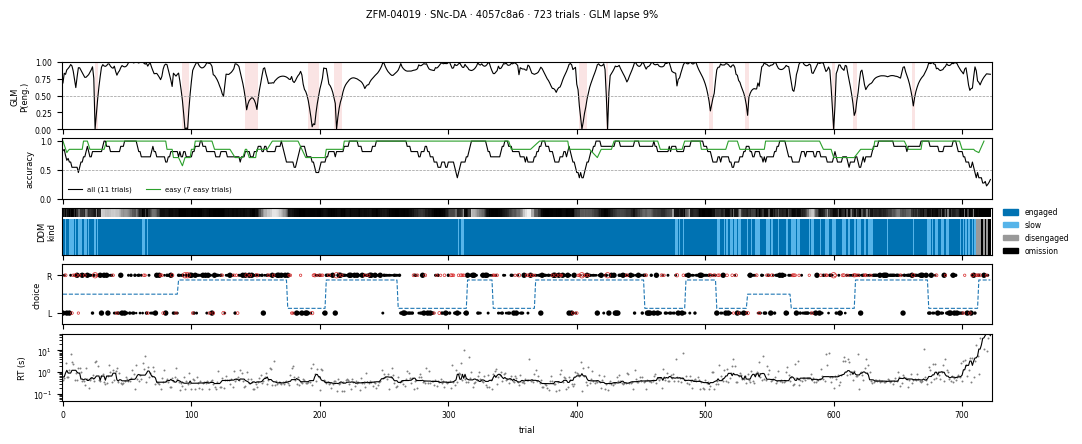

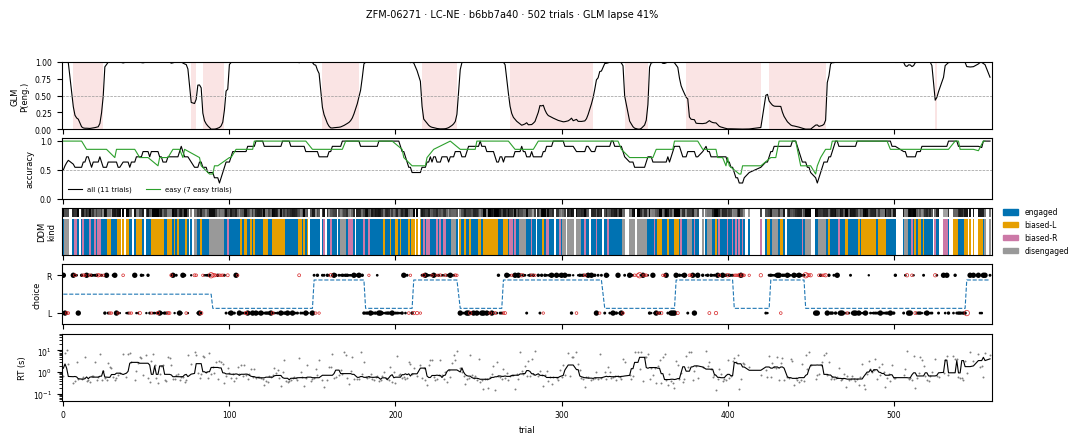

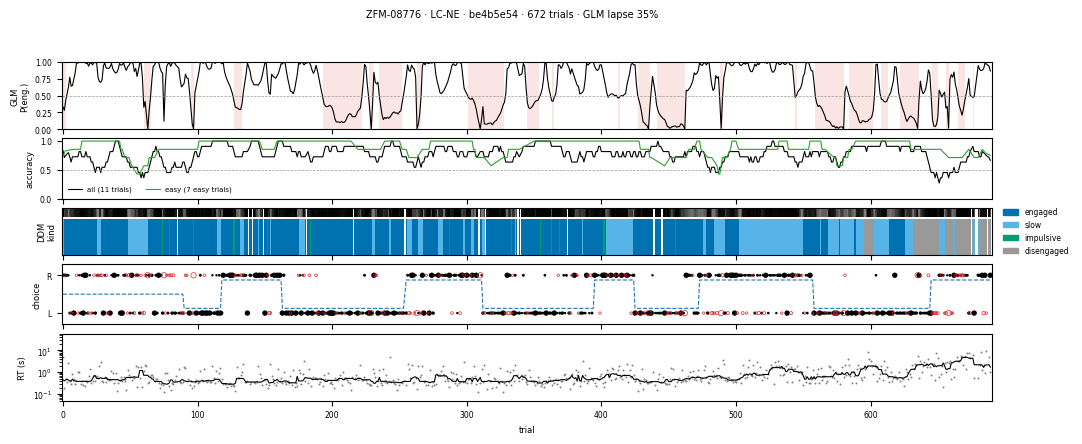

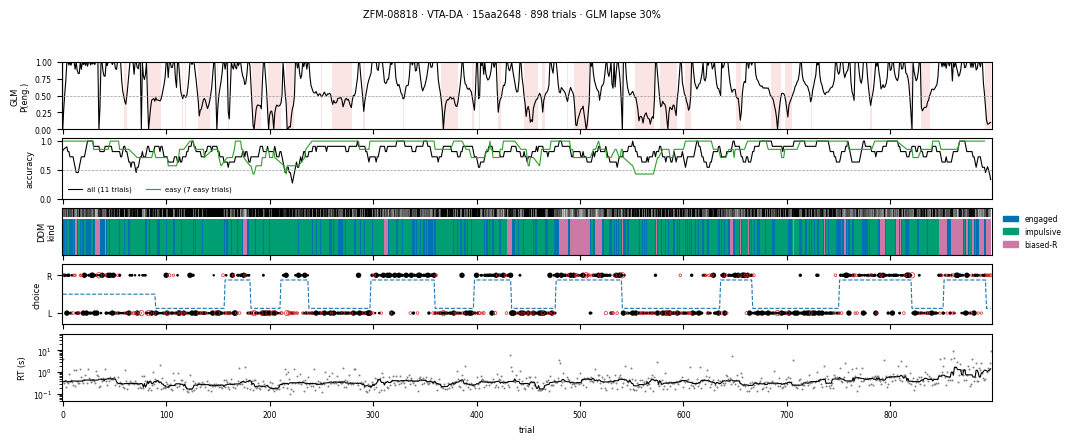

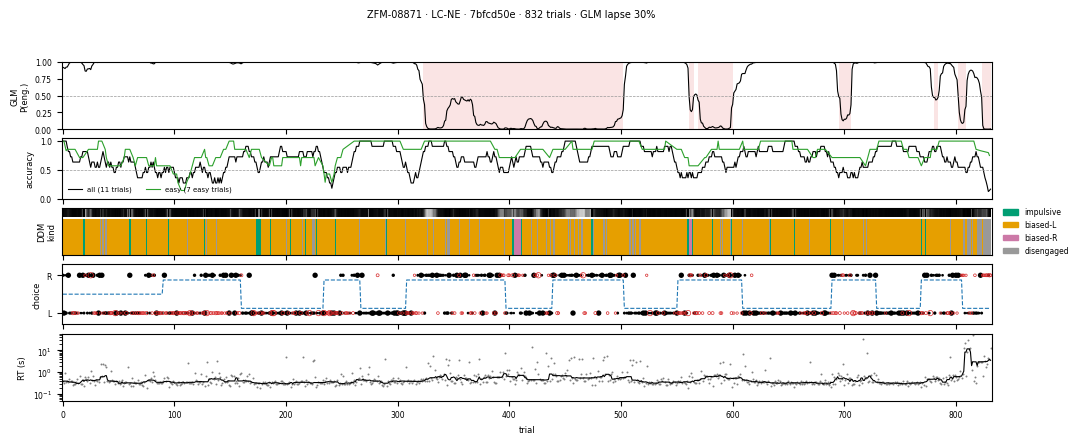

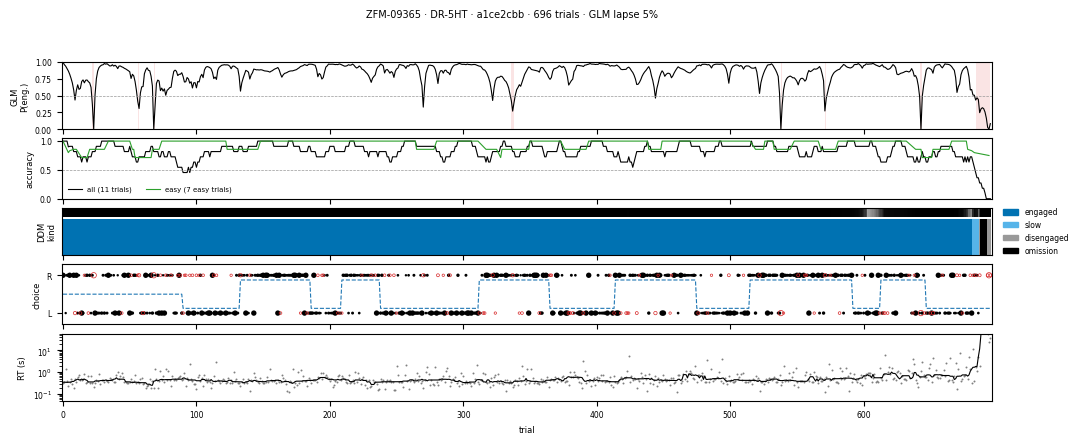

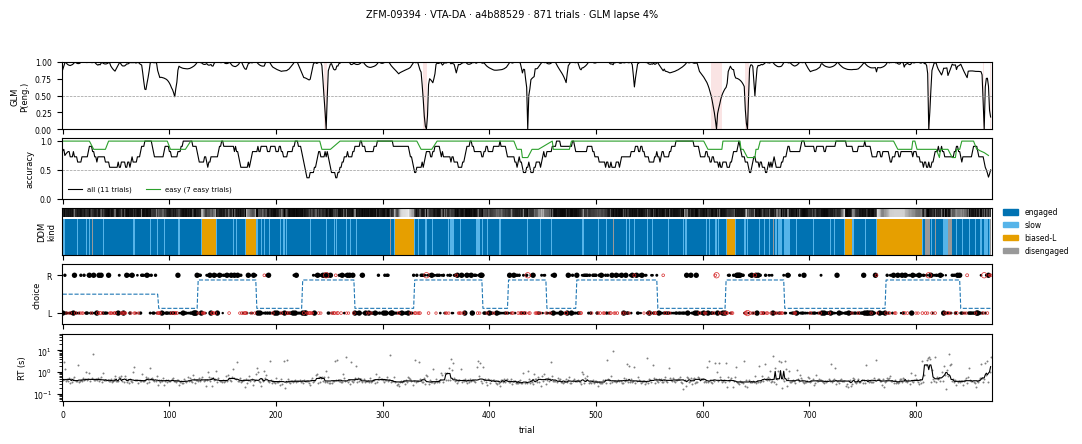

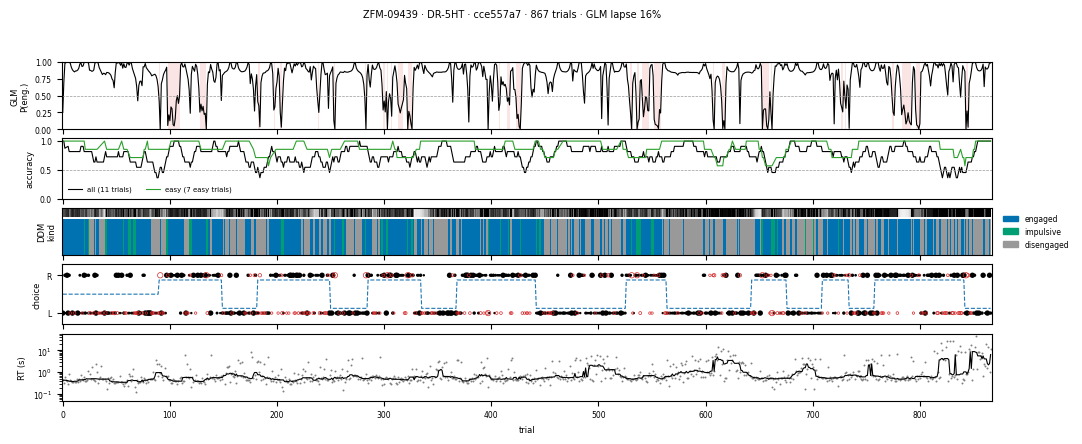

In [7]:
from matplotlib.colors import to_rgba

def example_session(eid, ax):
    g = T[T['eid'] == eid].sort_values('trial')
    x = g['trial'].to_numpy()
    # 1. GLM-HMM
    a = ax[0]
    a.plot(x, g['p_engaged'], color='k', lw=0.8)
    a.axhline(0.5, color='0.6', lw=0.5, ls='--')
    a.fill_between(x, 0, 1, where=g['p_engaged'] < 0.5, color='C3', alpha=0.12, lw=0, step='mid')
    a.set_ylim(0, 1); a.set_ylabel('GLM\nP(eng.)', fontsize=6)
    # 2. performance: rolling accuracy over all trials and over easy trials (>= 25% contrast)
    a = ax[1]
    a.plot(x, g['correct'].rolling(11, center=True, min_periods=3).mean(), color='k', lw=0.8, label='all (11 trials)')
    e = g[g['contrast'] >= 25]
    a.plot(e['trial'], e['correct'].rolling(7, center=True, min_periods=3).mean(), color='C2', lw=0.8,
           label='easy (7 easy trials)')
    a.axhline(0.5, color='0.6', lw=0.5, ls='--')
    a.set_ylim(0, 1.05); a.set_ylabel('accuracy', fontsize=6)
    a.legend(fontsize=5, frameon=False, ncol=2, loc='lower left')
    # 3. DDM-HMM kinds + certainty
    a = ax[2]
    cols = [to_rgba(st.KIND_COLORS[k]) for k in g['kind']]
    a.bar(x, 1, width=1, color=cols, lw=0)
    post = g.filter(like='p_state_').to_numpy()[np.arange(len(g)), np.clip(g['state'].to_numpy() - 1, 0, None)]
    a.bar(x, 0.25, bottom=1.05, width=1, color=[(0, 0, 0, p) for p in np.clip(np.nan_to_num(post), 0, 1)], lw=0)
    a.set_ylim(0, 1.3); a.set_yticks([]); a.set_ylabel('DDM\nkind', fontsize=6)
    # 4. choices
    a = ax[3]
    side = g['choice_right'].map({1.: 1, 0.: -1})
    size = 3 + 12 * g['contrast'].fillna(0) / 100
    ok = g['correct'] == 1
    a.scatter(x[ok], side[ok], s=size[ok], color='k', lw=0)
    a.scatter(x[~ok], side[~ok], s=size[~ok], facecolor='none', edgecolor='C3', lw=0.5)
    a.plot(x, (g['probabilityLeft'] - 0.5) * -2.5, color='C0', lw=0.8, ls='--')
    a.set_ylim(-1.6, 1.6); a.set_yticks([-1, 1], ['L', 'R']); a.set_ylabel('choice', fontsize=6)
    # 5. RT
    a = ax[4]
    rt = g['rt'].clip(lower=0.05)
    a.scatter(x, rt, s=2, color='0.5', lw=0)
    a.plot(x, rt.rolling(11, center=True, min_periods=3).median(), color='k', lw=0.8)
    a.set_yscale('log'); a.set_ylim(0.05, 60); a.set_ylabel('RT (s)', fontsize=6)
    for a in ax:
        a.tick_params(labelsize=5.5); a.set_xlim(x.min() - 1, x.max() + 1)
    ax[-1].set_xlabel('trial', fontsize=6)

EXAMPLES = []
for m, gm in T.groupby('subject'):
    n = gm.groupby('eid').size()
    EXAMPLES.append(n.index[np.argsort(n.to_numpy())[len(n) // 2]])
for eid in EXAMPLES:
    g = T[T['eid'] == eid]
    fig, ax = plt.subplots(5, 1, figsize=(12, 4.4), sharex=True, gridspec_kw={'height_ratios': [1, 0.9, 0.7, 0.9, 1], 'hspace': 0.15})
    example_session(eid, ax)
    kinds = [k for k in KINDS if k in g['kind'].unique()]
    handles = [plt.Rectangle((0, 0), 1, 1, color=st.KIND_COLORS[k]) for k in kinds]
    ax[2].legend(handles, kinds, fontsize=5.5, frameon=False, ncol=1, loc='center left', bbox_to_anchor=(1.005, 0.5))
    fig.suptitle(f"{g['subject'].iat[0]} · {g['target_NM'].iat[0]} · {eid[:8]} · {len(g)} trials · "
                 f"GLM lapse {np.mean(g['glm_state'] == 'lapse'):.0%}", fontsize=7, y=1.0)
    plt.show()

## Different timescales?

The GLM-HMM is sticky (states last tens of trials), and the DDM-HMM switches almost trial by trial (median Viterbi run ~2 trials, `../2_ddm_hmm_states.ipynb`). If they disagree only because of timescale, a smoothed DDM kind should track the GLM-HMM much better. Below:
1. median run length (trials) of each model's state, per mouse;
2. per mouse, the correlation between P(engaged) and the fraction of trials of each DDM kind in a centred window of 1 (raw) or 21 trials.

median run length (trials):
           ZFM-04019  ZFM-06271  ZFM-08776  ZFM-08818  ZFM-08871  ZFM-09365  ZFM-09394  ZFM-09439
GLM state       10.0       22.0        8.0        6.0       33.0        8.0       12.0        4.0
DDM kind         2.0        2.0        5.0        2.0        2.0        4.0        2.0        2.0


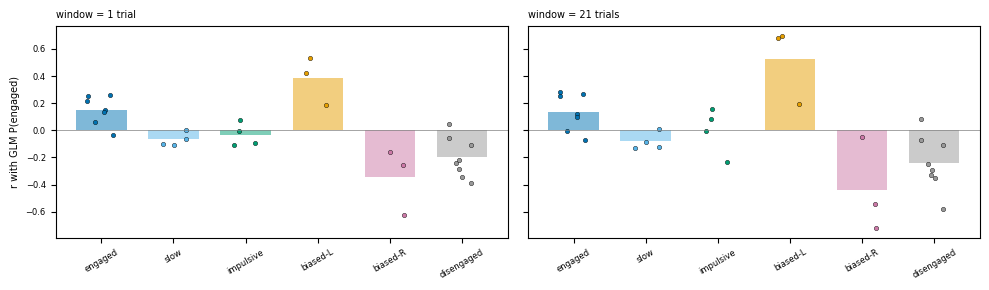

kind,engaged,slow,impulsive,biased-L,biased-R,disengaged
window,,,,,,
1,0.15,-0.07,-0.03,0.38,-0.35,-0.20
21,0.14,-0.08,0.00,0.52,-0.44,-0.24


In [8]:
def run_lengths(s):
    change = s.ne(s.shift()).cumsum()
    return s.groupby(change).size()

runs = pd.DataFrame({m: {'GLM state': np.median(np.concatenate([run_lengths(g['glm_state']).to_numpy() for _, g in gm.groupby('eid')])),
                         'DDM kind': np.median(np.concatenate([run_lengths(g['kind']).to_numpy() for _, g in gm.groupby('eid')]))}
                     for m, gm in T.groupby('subject')}).T
print('median run length (trials):'); print(runs.round(1).T.to_string())

rows = []
for w in (1, 21):
    for m, gm in T.groupby('subject'):
        for k in KINDS[:-1]:
            frac = gm.groupby('eid')['kind'].transform(lambda s: (s == k).astype(float).rolling(w, center=True, min_periods=1).mean())
            if frac.std() > 0:
                rows.append({'window': w, 'subject': m, 'kind': k, 'r': np.corrcoef(frac, gm['p_engaged'])[0, 1]})
R = pd.DataFrame(rows).pivot_table(index=['window', 'subject'], columns='kind', values='r')[KINDS[:-1]]
fig, axes = plt.subplots(1, 2, figsize=(10, 3), sharey=True)
for ax, w in zip(axes, (1, 21)):
    d = R.loc[w]
    for j, k in enumerate(d.columns):
        v = d[k].dropna()
        ax.bar(j, v.mean(), color=st.KIND_COLORS[k], alpha=0.5, width=0.7)
        ax.scatter(j + np.random.default_rng(j).uniform(-0.2, 0.2, len(v)), v, s=10, color=st.KIND_COLORS[k], ec='k', lw=0.3)
    ax.axhline(0, color='0.5', lw=0.5); ax.set_xticks(range(len(d.columns)), d.columns, fontsize=6, rotation=30)
    ax.set_title(f'window = {w} trial{"s" if w > 1 else ""}', fontsize=7, loc='left'); ax.tick_params(labelsize=6)
axes[0].set_ylabel('r with GLM P(engaged)', fontsize=7)
plt.tight_layout(); plt.show()
R.groupby('window').mean().round(2)

## Is DDM "impulsive" more than "fast"?

Only 3 mice have both an engaged and an impulsive state: ZFM-08776 (500 impulsive trials), ZFM-08818 and ZFM-09439. Tests, from most to least circular:
1. **DDM parameters.** Impulsive has a lower bound B (less evidence before committing) and a lower drift gain k. That is by construction: these are the fitted parameters.
2. **Easy-trial accuracy at matched RT** (quintiles of log RT). This is **circular**: the state on trial t is inferred from that trial's own choice and RT, so a fast error is pulled into the impulsive state.
3. **Early first movement** (wheel moves < 80 ms after stimulus onset, i.e. before the stimulus can be processed) at matched response RT. The model does not see first-movement times, so this is partly independent.
4. **The non-circular test.** Label trial t by the DDM kind of trial t−1, and compare trial t's easy-trial accuracy at matched RT. If impulsive is a state that persists, trials after an impulsive trial should also be less accurate. The test only makes sense where the state persists: P(impulsive at t | impulsive at t−1) vs its base rate.

In [9]:
MICE_I = [m for m, g in T.groupby('subject') if {'engaged', 'impulsive'} <= set(g['kind'])]
G = T[T['subject'].isin(MICE_I) & T['kind'].isin(['engaged', 'impulsive']) & (T['choice'] != 0)].copy()
G['rtbin'] = pd.qcut(np.log(G['rt'].clip(lower=0.03)), 5, labels=False)
G['early move'] = (G['rt_move'] < 0.08).astype(float)

def matched(d, col, by='kind', min_n=20):
    a = d.groupby(['subject', 'rtbin', by])[col].agg(['mean', 'size']).reset_index()
    a = a[a['size'] >= min_n].pivot_table(index=['subject', 'rtbin'], columns=by, values='mean').dropna()
    return a.groupby('subject').mean()

Ts = T.sort_values(['eid', 'trial']).copy()
Ts['prev kind'] = Ts.groupby('eid')['kind'].shift(1)
H = Ts[Ts['subject'].isin(MICE_I) & Ts['prev kind'].isin(['engaged', 'impulsive']) & (Ts['choice'] != 0) & (Ts['contrast'] >= 25)].copy()
H['rtbin'] = pd.qcut(np.log(H['rt'].clip(lower=0.03)), 5, labels=False)
persist = {m: ((Ts[(Ts.subject == m) & (Ts['prev kind'] == 'impulsive')]['kind'] == 'impulsive').mean(),
               (Ts[Ts.subject == m]['kind'] == 'impulsive').mean()) for m in MICE_I}

out = pd.concat({'easy acc, same trial (circular)': matched(G[G['contrast'] >= 25], 'correct'),
                 'early first move': matched(G, 'early move'),
                 'easy acc on t, by kind of t−1': matched(H, 'correct', by='prev kind', min_n=15)}, axis=1)
out[('persistence', 'P(imp | imp at t−1)')] = [persist[m][0] for m in out.index]
out[('persistence', 'base rate')] = [persist[m][1] for m in out.index]
out.round(3)

easy acc, same trial (circular)           early first move  \
kind                              engaged impulsive          engaged   
subject                                                                
ZFM-08776                           0.787     0.641            0.329   
ZFM-08818                           1.000     0.823            0.067   
ZFM-09439                           0.962     0.483            0.088   

                    easy acc on t, by kind of t−1            \
kind      impulsive                       engaged impulsive   
subject                                                       
ZFM-08776     0.289                         0.887     0.880   
ZFM-08818     0.090                         0.886     0.898   
ZFM-09439     0.197                         0.899     0.877   

                  persistence            
kind      P(imp | imp at t−1) base rate  
subject                                  
ZFM-08776               0.034     0.022  
ZFM-08818               0.707     0.425  
ZFM-09439               0.492     0.139

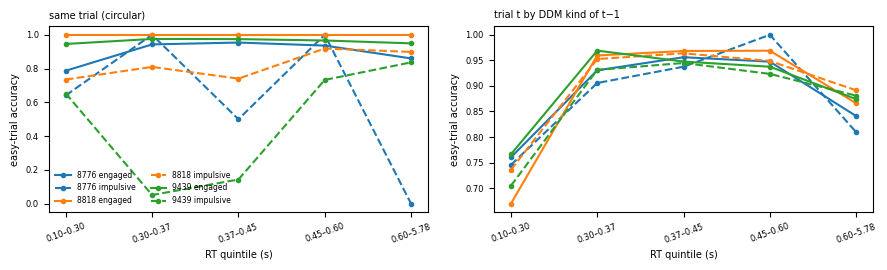

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(9, 2.8))
acc = G[G['contrast'] >= 25].groupby(['subject', 'rtbin', 'kind'])['correct'].mean().unstack()
edges = np.exp(pd.qcut(np.log(G['rt'].clip(lower=0.03)), 5, retbins=True)[1])
for m, c in zip(MICE_I, ['C0', 'C1', 'C2']):
    for k, ls in [('engaged', '-'), ('impulsive', '--')]:
        axes[0].plot(acc.loc[m].index, acc.loc[m][k], color=c, ls=ls, marker='o', ms=3, label=f'{m[-4:]} {k}')
    pc = H[H.subject == m].groupby(['rtbin', 'prev kind'])['correct'].mean().unstack()
    for k, ls in [('engaged', '-'), ('impulsive', '--')]:
        axes[1].plot(pc.index, pc[k], color=c, ls=ls, marker='o', ms=3)
axes[0].set_title('same trial (circular)', fontsize=7, loc='left'); axes[1].set_title('trial t by DDM kind of t−1', fontsize=7, loc='left')
for a in axes:
    a.set_xticks(range(5), [f'{edges[i]:.2f}–{edges[i+1]:.2f}' for i in range(5)], fontsize=5.5, rotation=20)
    a.set_xlabel('RT quintile (s)', fontsize=7); a.set_ylabel('easy-trial accuracy', fontsize=7); a.tick_params(labelsize=6)
axes[0].legend(fontsize=5.5, frameon=False, ncol=2)
plt.tight_layout(); plt.show()

**Reading.** The evidence that impulsive is a *state* rather than a label on fast errors is weak:
- At matched RT, impulsive trials are less accurate (by 0.13–0.48), but that is circular.
- Early first movements are more common in impulsive trials in only 1 of 3 mice (ZFM-09439) once response RT is matched.
- The non-circular test fails. Where the state persists (ZFM-08818: P(imp | imp) = .71 vs .43; ZFM-09439: .49 vs .14), trials after an impulsive trial are just as accurate as trials after an engaged one, at matched RT.
- In ZFM-08776 the impulsive state does not persist at all (.03 vs .02): it's a per-trial label for the fastest trials.

So, with 3 mice and these fits, DDM "impulsive" mostly marks fast trials that ended in errors, not a lasting mode of fast guessing. A behavioural signature independent of the model (wheel movement during quiescence, pre-stimulus paw/whisker vigor) would be the stronger test, and is analysis C's job.

## Does the DDM-HMM fit the temporal structure?

The DDM-HMM switches every 2–3 trials in most mice. Either behaviour really changes that fast, or the chain is being used as a *mixture* (states that soak up parts of the RT distribution, e.g. fast errors) and misses the slow structure. Three checks:
1. **Fitted vs decoded stickiness.** Fitted self-transition per state vs the Viterbi stay rate, and how certain the posteriors are. Also whether EM converged.
2. **Does the chain reproduce the autocorrelation of behaviour?** Under the HMM, trials are independent given the state. So the autocorrelation of log RT (and of accuracy) across trials must come from the chain: Cov(lag) = Σᵢⱼ πᵢ (Tˡᵃᵍ)ᵢⱼ fᵢ fⱼ, with fᵢ the state means. Compare it to the data's (contrast means removed, pairs within a session).
3. **What is left** after subtracting each trial's posterior-expected state mean. If the states capture the temporal structure, this residual autocorrelation is ~0.

In [11]:
D, S = st.load_ddm()
_, params = st.dh.load_all()
rows = []
for m, g in D.groupby('subject'):
    z = g.sort_values(['session_idx', 'trial'])
    same = z['state'].eq(z.groupby('eid')['state'].shift(-1))[z.groupby('eid').cumcount(ascending=False) > 0]
    post = g.filter(like='p_state_').max(1)
    for s, x in g.groupby('state'):
        rows.append({'subject': m, 'state': s, 'kind': x['kind'].iat[0], 'occupancy': len(x) / len(g),
                     'fitted self-transition': S.attrs['trans'][m].loc[s, s],
                     'Viterbi stay rate': same[z.loc[same.index, 'state'] == s].mean()})
stick = pd.DataFrame(rows)
stick = stick[stick['occupancy'] > 0.01]
stick['fitted dwell (trials)'] = 1 / (1 - stick['fitted self-transition'])
mouse = params.groupby('subject').agg(format=('format', 'first'), EM_converged=('converged', 'first'),
                                      iterations=('iterations', 'first'))
mouse['median max posterior'] = D.groupby('subject').apply(lambda g: g.filter(like='p_state_').max(1).median())
mouse['max posterior > 0.9'] = D.groupby('subject').apply(lambda g: (g.filter(like='p_state_').max(1) > 0.9).mean())
mouse['occupancy-weighted dwell'] = stick.groupby('subject').apply(lambda x: np.average(x['fitted dwell (trials)'], weights=x['occupancy']))
display(mouse.round(2))
stick.set_index(['subject', 'state']).round(2)

,format,EM_converged,iterations,median max posterior,max posterior > 0.9,occupancy-weighted dwell
subject,,,,,,
ZFM-04019,new,False,1000.0,0.85,0.38,5.61
ZFM-06271,legacy,None,NaN,0.77,0.25,2.82
ZFM-08776,legacy,None,NaN,0.98,0.73,12.87
ZFM-08818,new,False,1000.0,0.75,0.35,4.50
ZFM-08871,new,False,1000.0,0.95,0.66,5.23
ZFM-09365,new,False,1000.0,0.99,0.80,156.50
ZFM-09394,new,False,1000.0,0.91,0.52,9.05
ZFM-09439,new,False,1000.0,0.77,0.29,2.68


kind  occupancy  fitted self-transition  \
subject   state                                                  
ZFM-04019 1         engaged       0.39                    0.53   
          2         engaged       0.29                    0.93   
          3      disengaged       0.04                    0.65   
          4            slow       0.26                    0.48   
          5        omission       0.02                    0.61   
ZFM-06271 1      disengaged       0.14                    0.85   
          2        biased-L       0.24                    0.62   
          3         engaged       0.53                    0.50   
          4        biased-R       0.10                    0.49   
ZFM-08776 1         engaged       0.62                    0.91   
          2      disengaged       0.15                    0.97   
          3       impulsive       0.02                    0.03   
          4            slow       0.21                    0.84   
ZFM-08818 1        biased-R       0.17                    0.63   
          2         engaged       0.29                    0.34   
          3       impulsive       0.43                    0.70   
          4      disengaged       0.12                    0.95   
ZFM-08871 1        biased-R       0.19                    0.81   
          2        biased-L       0.63                    0.84   
          3      disengaged       0.09                    0.33   
          4       impulsive       0.08                    0.47   
ZFM-09365 1      disengaged       0.05                    0.78   
          2         engaged       0.48                    1.00   
          3            slow       0.13                    0.91   
          4         engaged       0.34                    0.99   
ZFM-09394 1            slow       0.14                    0.38   
          2        biased-L       0.42                    0.94   
          3         engaged       0.38                    0.73   
          4      disengaged       0.06                    0.57   
ZFM-09439 1       impulsive       0.14                    0.51   
          2         engaged       0.37                    0.64   
          3      disengaged       0.35                    0.68   
          4         engaged       0.14                    0.49   

                 Viterbi stay rate  fitted dwell (trials)  
subject   state                                            
ZFM-04019 1                   0.60                   2.13  
          2                   0.98                  14.17  
          3                   0.67                   2.86  
          4                   0.44                   1.91  
          5                   0.66                   2.59  
ZFM-06271 1                   0.78                   6.73  
          2                   0.60                   2.66  
          3                   0.62                   2.01  
          4                   0.20                   1.97  
ZFM-08776 1                   0.93                  11.42  
          2                   0.97                  29.43  
          3                   0.03                   1.04  
          4                   0.86                   6.08  
ZFM-08818 1                   0.75                   2.68  
          2                   0.45                   1.51  
          3                   0.71                   3.29  
          4                   0.96                  19.15  
ZFM-08871 1                   0.87                   5.22  
          2                   0.87                   6.21  
          3                   0.32                   1.48  
          4                   0.39                   1.87  
ZFM-09365 1                   0.83                   4.56  
          2                   1.00                 256.85  
          3                   0.94                  11.11  
          4                   0.99                  93.56  
ZFM-09394 1                   0.36                   1.62  
          2                   0.

data                                            \
lag                 1     2     3     5     10    20    50    100   
        subject                                                     
logRT   ZFM-04019  0.26  0.25  0.23  0.21  0.20  0.16  0.13  0.10   
        ZFM-06271  0.23  0.10 -0.00  0.06 -0.01 -0.10 -0.04 -0.01   
        ZFM-08776  0.55  0.52  0.51  0.50  0.48  0.45  0.40  0.32   
        ZFM-08818  0.42  0.40  0.39  0.38  0.35  0.30  0.23  0.17   
        ZFM-08871  0.30  0.31  0.28  0.26  0.21  0.15  0.09  0.07   
        ZFM-09365  0.51  0.50  0.48  0.47  0.45  0.41  0.34  0.28   
        ZFM-09394  0.41  0.39  0.38  0.36  0.32  0.26  0.19  0.17   
        ZFM-09439  0.43  0.42  0.42  0.41  0.37  0.31  0.21  0.18   
correct ZFM-04019  0.06  0.05  0.06  0.02  0.04  0.01  0.00  0.02   
        ZFM-06271  0.14  0.07  0.03  0.10  0.08  0.01  0.07 -0.07   
        ZFM-08776  0.08  0.08  0.07  0.06  0.04  0.03  0.01  0.03   
        ZFM-08818  0.09  0.07  0.07  0.05  0.04  0.02  0.02  0.01   
        ZFM-08871  0.07  0.09  0.07  0.07  0.04  0.03  0.02  0.01   
        ZFM-09365  0.05  0.04  0.03  0.04  0.03  0.01  0.01 -0.00   
        ZFM-09394  0.11  0.10  0.09  0.07  0.06  0.04  0.00  0.03   
        ZFM-09439  0.11  0.10  0.10  0.09  0.07  0.04 -0.00  0.02   

                  implied by chain        ...             left after states  \
lag                            1     2    ...   50    100               1     
        subject                           ...                                 
logRT   ZFM-04019             0.27  0.20  ...  0.00  0.00              0.06   
        ZFM-06271             0.16  0.13  ...  0.00  0.00              0.11   
        ZFM-08776             0.60  0.57  ...  0.08  0.01             -0.04   
        ZFM-08818             0.33  0.31  ...  0.02  0.00              0.10   
        ZFM-08871             0.17  0.05  ...  0.00  0.00              0.17   
        ZFM-09365             0.73  0.68  ...  0.43  0.31              0.05   
        ZFM-09394             0.43  0.27  ...  0.00  0.00              0.06   
        ZFM-09439             0.25  0.21  ...  0.02  0.00              0.18   
correct ZFM-04019             0.03  0.02  ...  0.00  0.00              0.05   
        ZFM-06271             0.04  0.03  ...  0.00  0.00              0.13   
        ZFM-08776             0.03  0.03  ...  0.00  0.00              0.06   
        ZFM-08818             0.01  0.01  ...  0.00  0.00              0.09   
        ZFM-08871             0.00  0.00  ...  0.00  0.00              0.06   
        ZFM-09365             0.02  0.02  ...  0.01  0.01              0.03   
        ZFM-09394             0.01  0.01  ...  0.00  0.00              0.10   
        ZFM-09439             0.01  0.00  ...  0.00  0.00              0.12   

                                                             
lag                 2     3     5     10    20    50    100  
        subject                                              
logRT   ZFM-04019  0.08  0.07  0.07  0.08  0.06  0.04  0.03  
        ZFM-06271  0.03 -0.05  0.04 -0.01 -0.08 -0.02 -0.02  
        ZFM-08776 -0.00  0.03  0.02  0.02  0.01  0.01  0.01  
        ZFM-08818  0.10  0.10  0.10  0.08  0.06  0.04  0.03  
        ZFM-08871  0.18  0.17  0.15  0.11  0.07  0.04  0.05  
        ZFM-09365  0.05  0.04  0.04  0.04  0.02  0.01  0.02  
        ZFM-09394  0.09  0.08  0.07  0.06  0.04  0.01  0.03  
        ZFM-09439  0.20  0.20  0.19  0.15  0.11  0.06  0.06  
correct ZFM-04019  0.04  0.05  0.01  0.03  0.01 -0.00  0.01  
        ZFM-06271  0.06  0.02  0.07  0.05  0.02  0.06 -0.04  
        ZFM-08776  0.06  0.05  0.05  0.03  0.02 -0.00  0.02  
        ZFM-08818  0.06  0.07  0.04  0.02  0.00  0.01  0.00  
        ZFM-08871  0.08  0.07  0.06  0.04  0.02  0.02  0.01  
        ZFM-09365  0.03  0.02  0.03  0.02  0.00  0.01 -0.01  
        ZFM-09394  0.08  0.08  0.07  0.06  0.04  0.01  0.03  
        ZFM-09439  0.11  0.11  0.10  0.07  0.04 -0.01  0.02  

[16 rows x 24 columns]

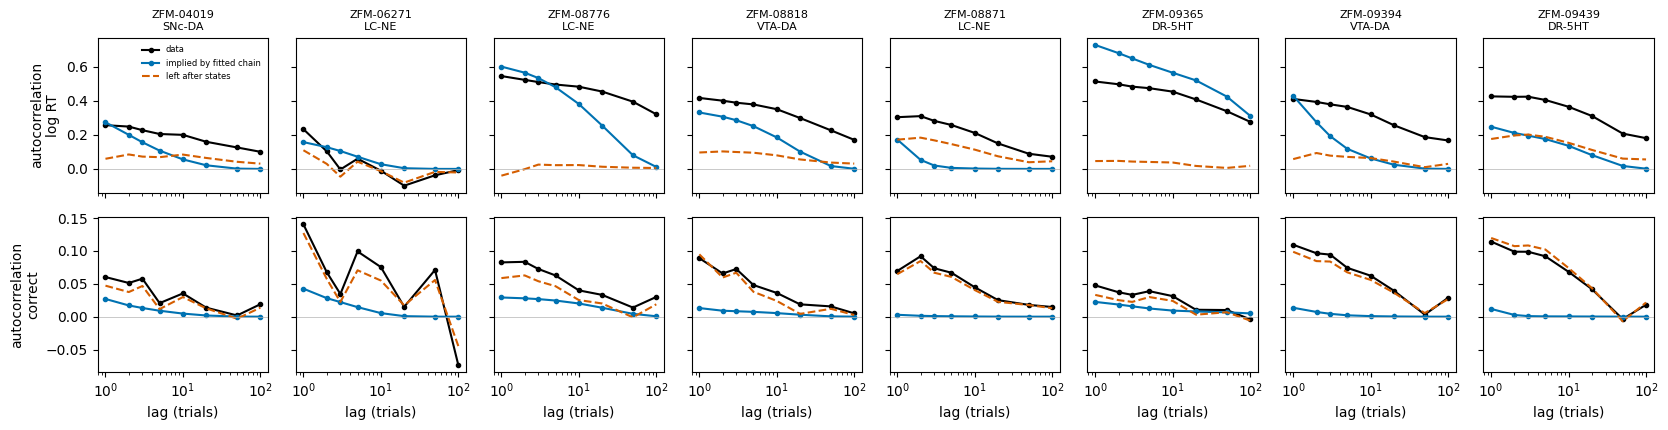

In [12]:
LAGS = np.array([1, 2, 3, 5, 10, 20, 50, 100])
acfs = {v: st.temporal_check(D, S.attrs['trans'], LAGS, v) for v in ['logRT', 'correct']}
fig, axes = plt.subplots(2, len(MICE), figsize=(2.1 * len(MICE), 4.4), sharex=True, sharey='row')
for r, (v, A) in enumerate(acfs.items()):
    for ax, m in zip(axes[r], MICE):
        a = A[A['subject'] == m]
        ax.plot(a['lag'], a['data'], 'k-o', ms=3, label='data')
        ax.plot(a['lag'], a['implied by chain'], '-o', c='#0072B2', ms=3, label='implied by fitted chain')
        ax.plot(a['lag'], a['left after states'], '--', c='#D55E00', label='left after states')
        ax.axhline(0, c='0.7', lw=0.5)
        ax.set_xscale('log')
        if r == 0:
            ax.set_title(f'{m}\n{NM[m]}', fontsize=8)
        else:
            ax.set_xlabel('lag (trials)')
    axes[r, 0].set_ylabel(f'autocorrelation\n{"log RT" if v == "logRT" else "correct"}')
axes[0, 0].legend(fontsize=6, frameon=False)
fig.tight_layout()
pd.concat({v: A.pivot(index='subject', columns='lag') for v, A in acfs.items()}).round(2)

**Reading.** The fitted chain is switchy, and it does not reproduce how behaviour changes over time.
- **The switching is in the fit, not in the decoding.** Viterbi stay rates match the fitted self-transitions. In 6 of 8 mice the occupancy-weighted dwell is 3–9 trials, and in the switchiest ones the posteriors are uncertain (median max posterior 0.75–0.85, under 40% of trials above 0.9). The exceptions are ZFM-09365 (dwells of 100–250 trials) and ZFM-08776 (sticky, except an "impulsive" state with self-transition 0.03, i.e. a pure mixture component). The new-format fits all stopped at the 1000-iteration EM cap without converging.
- **Log RT is correlated over ~100 trials; the chain forgets in ~5–20.** In the data, the autocorrelation of log RT is still 0.1–0.3 at lag 100. In the switchy mice, the fitted chain implies it should be gone by lag 20–50, and the posterior states leave 0.1–0.2 residual autocorrelation at short lags (ZFM-08871, 08818, 09439). ZFM-06271 has one session and its curves are noise. The two sticky fits are the ones that capture RT (08776 residual ≈ 0); 09365 overshoots (implied > data).
- **Accuracy streaks are not captured at all.** Correct/error is autocorrelated (0.05–0.11 at lag 1, also after removing block × side × contrast); the chain implies < 0.03 and subtracting the states leaves it unchanged.

So in most mice the K=4 DDM-HMM works more like a **mixture over RT/accuracy regimes** than a model of slow state dynamics: it uses fast switching to fit the shape of the RT distribution (fast errors, long tails) and misses the slow drift and the accuracy streaks. This explains why "impulsive" behaves like a label on fast errors, and why the DDM kinds don't line up with the sticky GLM-HMM.

What would test this properly (needs the collaborator's fitting code): compare held-out log-likelihood of the HMM vs the same K-state *mixture* (transitions fixed to the occupancy), refit with a sticky prior on the diagonal and see how much likelihood is lost, and add a slow covariate (trial position / session drift) so the states don't have to absorb it.

## Do the two models switch together?

Per session: the switch rate of each model = fraction of consecutive trial pairs where the state changes. GLM-HMM: the most likely state (P(engaged) ≥ 0.5 or not). DDM-HMM: the Viterbi state (`state`, all K+1 states) and, more coarsely, the named kind (two engaged states count as one).
- **Within mouse:** Spearman r across that mouse's sessions (only mice with ≥ 5 sessions). This is the real test: same model parameters, different days.
- **Between mice:** r of the mouse means (n = 8, so only indicative). Between mice, the rates mostly reflect each fit's transition matrix.

within mouse: mean r = +0.11, 5/7 positive, Wilcoxon p = 0.578
between mice: r = -0.10 (n = 8)


,NM,sessions,GLM switch rate,DDM switch rate,r within (ddm_state),p (ddm_state),r within (ddm_kind),p (ddm_kind),"r within, partial session length"
subject,,,,,,,,,
ZFM-04019,SNc-DA,20,0.032,0.345,0.301,0.198,0.305,0.191,0.101
ZFM-06271,LC-NE,1,0.040,0.405,NaN,NaN,NaN,NaN,NaN
ZFM-08776,LC-NE,33,0.076,0.098,0.143,0.428,0.143,0.428,0.162
ZFM-08818,VTA-DA,21,0.093,0.331,-0.275,0.227,-0.275,0.227,-0.281
ZFM-08871,LC-NE,35,0.018,0.224,0.175,0.314,0.175,0.314,0.166
ZFM-09365,DR-5HT,43,0.046,0.025,0.248,0.109,0.267,0.083,0.298
ZFM-09394,VTA-DA,46,0.035,0.228,0.538,0.000,0.538,0.000,0.381
ZFM-09439,DR-5HT,41,0.064,0.291,-0.361,0.020,-0.361,0.020,-0.358


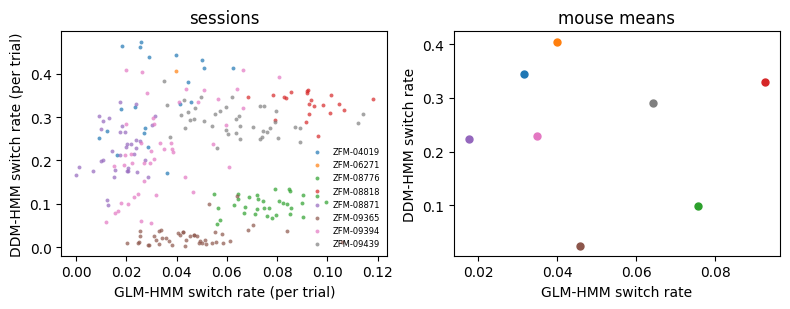

In [13]:
from scipy.stats import spearmanr, wilcoxon

def switch_rate(s):
    return s.ne(s.shift()).iloc[1:].mean()

R = (T.sort_values(['eid', 'trial']).groupby(['subject', 'eid'])
     .agg(glm=('glm_state', switch_rate), ddm_state=('state', switch_rate), ddm_kind=('kind', switch_rate),
          n=('trial', 'size'), p_lapse=('glm_state', lambda s: (s == 'lapse').mean()))
     .reset_index())
rows = []
for m, g in R.groupby('subject'):
    row = {'subject': m, 'NM': NM[m], 'sessions': len(g), 'GLM switch rate': g['glm'].mean(),
           'DDM switch rate': g['ddm_state'].mean()}
    if len(g) >= 5:
        for c in ('ddm_state', 'ddm_kind'):
            row[f'r within ({c})'], row[f'p ({c})'] = spearmanr(g['glm'], g[c])
        row['r within, partial session length'] = spearmanr(g['glm'] - np.polyval(np.polyfit(g['n'], g['glm'], 1), g['n']),
                                                            g['ddm_state'] - np.polyval(np.polyfit(g['n'], g['ddm_state'], 1), g['n']))[0]
    rows.append(row)
SW = pd.DataFrame(rows).set_index('subject')
w = SW['r within (ddm_state)'].dropna()
print(f"within mouse: mean r = {w.mean():+.2f}, {(w > 0).sum()}/{len(w)} positive, Wilcoxon p = {wilcoxon(w).pvalue:.3f}")
print(f"between mice: r = {spearmanr(SW['GLM switch rate'], SW['DDM switch rate'])[0]:+.2f} (n = {len(SW)})")
display(SW.round(3))

fig, axes = plt.subplots(1, 2, figsize=(8, 3.2))
for i, m in enumerate(MICE):
    g = R[R['subject'] == m]
    axes[0].scatter(g['glm'], g['ddm_state'], s=8, color=f'C{i}', label=m, alpha=0.7, lw=0)
    axes[1].scatter(SW.loc[m, 'GLM switch rate'], SW.loc[m, 'DDM switch rate'], color=f'C{i}', s=25)
axes[0].set(xlabel='GLM-HMM switch rate (per trial)', ylabel='DDM-HMM switch rate (per trial)', title='sessions')
axes[1].set(xlabel='GLM-HMM switch rate', ylabel='DDM-HMM switch rate', title='mouse means')
axes[0].legend(fontsize=6, frameon=False)
fig.tight_layout()

**Reading.** No consistent relation. Within mouse, the mean r is +0.11 (5 of 7 mice positive, Wilcoxon p = 0.58), and the two clear cases go opposite ways: ZFM-09394 +0.54 (p < 0.001) and ZFM-09439 −0.36 (p = 0.02). Controlling for session length changes nothing. Between mice r = −0.10. The rates are on different scales: the GLM-HMM switches 2–9% of trials, the DDM-HMM 3–40%, set mostly by each fit's transition matrix (ZFM-09365 and 08776 are the sticky DDM fits). This fits the rest of A: the models track different things, so a session that is "switchy" for one is not switchy for the other.

## Reading

- **The two models barely overlap.** Knowing the GLM-HMM state leaves 94% of the uncertainty about the DDM kind (mean over mice), and the reverse leaves 89%. The expected mapping (GLM lapse = DDM disengaged + impulsive + biased) does not hold. GLM *engaged* trials are only 50% DDM-engaged. GLM *lapse* trials are 38% DDM-engaged, and only 21% DDM-disengaged.
- **DDM "disengaged" is mostly about time, not choice.** Those trials have RTs of ~4–5 s. Inside the GLM-HMM engaged state they are still 89% correct on easy trials, so the GLM-HMM (rightly, for choices) calls them engaged. They do rise late in the session.
- **What the GLM-HMM lapse state tracks is side bias.** Across mice, P(engaged) goes up with biased-L and down with biased-R (r ≈ +0.4 / −0.4, 0.5 / −0.4 after smoothing). GLM lapse trials also repeat the previous choice more (0.77–0.93 vs 0.6–0.7). In these mice, the choice-only "lapse" state is largely a perseverative / side-biased mode, with accuracy dropping on easy trials.
- **It isn't just timescale.** GLM states last 4–33 trials, DDM kinds ~2–5. But smoothing the DDM kinds over 21 trials barely changes the correlations.
- **Check per mouse.** In ZFM-08871 the GLM-HMM did not separate accuracy (easy accuracy 0.86 vs 0.87): its two states are side states. ZFM-06271 has one session.
- **The DDM-HMM is mostly a mixture, not slow dynamics.** In most mice it switches every 3–9 trials, while log RT stays correlated over ~100 trials and accuracy over ~10. The fitted chain reproduces neither, and its states leave much of the RT autocorrelation and all of the accuracy streaks unexplained. Only ZFM-08776 and 09365 have sticky fits. EM hit its iteration cap in every new-format fit.
- **Their switch rates are unrelated.** Across a mouse's sessions, the GLM and DDM switch rates correlate r = +0.11 on average, with opposite significant cases (ZFM-09394 +0.54, 09439 −0.36).

**For B–C:** the two models are not nested descriptions of one engagement axis. They capture different things: the DDM-HMM, response timing (and through it disengagement and impulsivity); the GLM-HMM, stimulus-following vs side-biased choice. So B should ask which of the two, or both, the NMs follow, rather than whether the DDM "refines" GLM lapses.